# Transverse shear stresses

`Laminate.calc_transverse_shear_stress` gives the transverse shear stresses at
a height $z$ for given shear forces $Q_y$, $Q_x$, with the equilibrium
distribution that defines `Ats` for `shear_correction='rohwer'`, see
[Shear correction](../shear_correction.rst). The stresses vanish at the faces,
integrate to the shear forces, and their complementary energy is
$Q^T A_{ts}^{-1} Q / 2$, as checked by the unit test
`test_example_shear_stress_cross_ply` of `tests/test_transverse_shear.py`:

In [1]:
import sys
sys.path.insert(0, '../tests') # helpers of the tests

import numpy as np

import matplotlib.pyplot as plt

from composites import laminated_plate, isotropic_plate

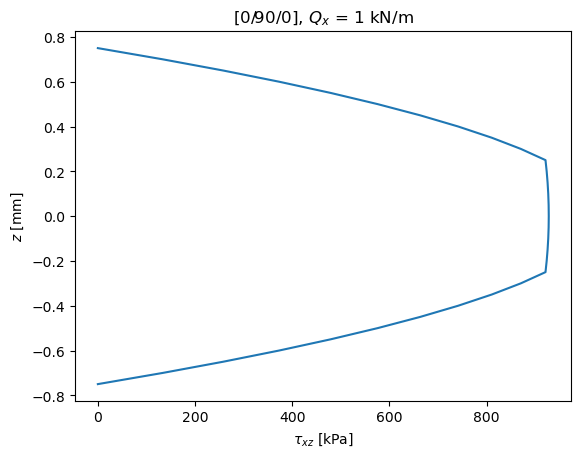

In [2]:
# [0/90/0] CFRP plate, SI units, under the shear force Qx only
laminaprop = (142e9, 8.7e9, 0.28, 5.1e9, 5.1e9, 3.2e9)
lam = laminated_plate([0, 90, 0], plyt=0.5e-3, laminaprop=laminaprop)
h = lam.h
Qy, Qx = 0., 1e3 # N/m
zs = np.linspace(-h/2, h/2, 31)
tau = np.array([lam.calc_transverse_shear_stress(z, Qy, Qx) for z in zs])
tau_yz, tau_xz = tau[:, 0], tau[:, 1]
tol = 1e-10*Qx/h
# traction-free faces
assert abs(tau_xz[0]) < tol and abs(tau_xz[-1]) < tol
# orthotropic plies in the laminate axes: Qx gives no tau_yz
assert np.allclose(tau_yz, 0, atol=tol)

plt.plot(tau_xz/1e3, zs*1e3)
plt.xlabel(r'$\tau_{xz}$ [kPa]')
plt.ylabel('$z$ [mm]')
plt.title('[0/90/0], $Q_x$ = 1 kN/m')
plt.show()

In [3]:
# the stresses integrate to the shear forces, and their complementary
# energy defines Ats: 1/2 Q^T Ats^-1 Q = int 1/2 tau^T Cs^-1 tau dz
Q = np.array([Qy, Qx])
xi, w = np.polynomial.legendre.leggauss(3)
zk = -h/2
resultant = np.zeros(2)
Ustar = 0.
for ply in lam.plies:
    Cs = np.asarray(ply.get_constitutive_matrix())[3:, 3:]
    for x, wi in zip(xi, w):
        z = zk + ply.h*(x + 1)/2
        t = np.array(lam.calc_transverse_shear_stress(z, Qy, Qx))
        resultant += wi*ply.h/2*t
        Ustar += wi*ply.h/2*0.5*t @ np.linalg.solve(Cs, t)
    zk += ply.h
assert np.allclose(resultant, Q, rtol=1e-12, atol=1e-12*Qx)
assert np.isclose(Ustar, 0.5*Q @ np.linalg.solve(lam.Ats, Q), rtol=1e-12)
# the constant-strain stiffness overestimates the shear stiffness
assert lam.scf_k13 < 1
print('resultant =', resultant)
print('Ustar = %.12e, Q^T Ats^-1 Q / 2 = %.12e' % (Ustar, 0.5*Q @ np.linalg.solve(lam.Ats, Q)))
print('scf_k13 =', lam.scf_k13)

resultant = [-9.46633086e-30  1.00000000e+03]
Ustar = 1.022608650554e-01, Q^T Ats^-1 Q / 2 = 1.022608650554e-01
scf_k13 = 0.7297695519315797


## Homogeneous plate

For a homogeneous plate the distribution is the parabola
$\tau_{xz} = 3 Q_x/(2h) (1 - 4 \bar{z}^2/h^2)$, with $\bar{z}$ measured from
the mid-surface, for any offset. The unit test `test_isotropic_parabola` of
`tests/test_transverse_shear.py` checks it for the offsets 0, +0.37 and -1.5:

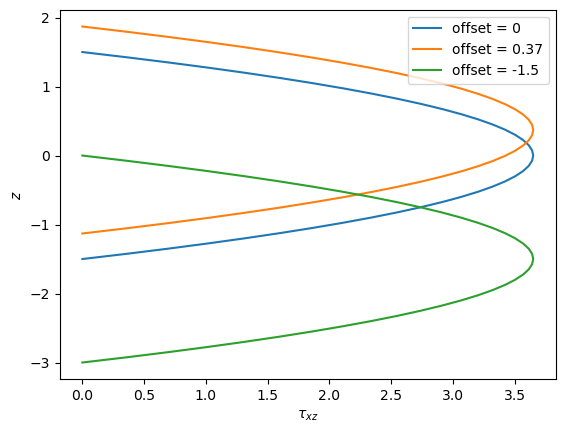

In [4]:
for offset in [0., +0.37, -1.5]:
    h = 3.
    lam = isotropic_plate(thickness=h, E=70e3, nu=0.3, offset=offset)
    Qx, Qy = 7.3, -2.1
    tol = 1e-13*3/(2*h) # machine precision relative to the peak stress
    for z in np.linspace(-h/2, h/2, 21) + offset:
        zbar = z - offset
        tau_yz, tau_xz = lam.calc_transverse_shear_stress(z, Qy, Qx)
        assert abs(tau_xz - 3*Qx/(2*h)*(1 - 4*zbar**2/h**2)) <= tol*abs(Qx)
        assert abs(tau_yz - 3*Qy/(2*h)*(1 - 4*zbar**2/h**2)) <= tol*abs(Qy)
        # no Qy contribution in tau_xz, and no Qx contribution in tau_yz
        assert abs(lam.calc_transverse_shear_stress(z, 1., 0.)[1]) <= tol
        assert abs(lam.calc_transverse_shear_stress(z, 0., 1.)[0]) <= tol
    zs = np.linspace(-h/2, h/2, 41) + offset
    plt.plot([lam.calc_transverse_shear_stress(z, Qy, Qx)[1] for z in zs], zs,
             label='offset = %g' % offset)
plt.xlabel(r'$\tau_{xz}$')
plt.ylabel('$z$')
plt.legend()
plt.show()

## A posteriori recovery from an FSDT solution

From the strain gradients of an actual FSDT solution,
`Laminate.calc_equilibrium_transverse_shear` recovers the stresses by
integrating the equilibrium equations through the thickness, and
`Laminate.calc_aposteriori_energy` gives their strain energies, here for a
homogeneous plate in cylindrical bending, recovering the factor 5/6 (unit test
`test_aposteriori_energy_homogeneous` of `tests/test_transverse_shear.py`):

In [5]:
h, E, nu = 2., 70e3, 0.3
G = E/(2*(1 + nu))
lam = isotropic_plate(thickness=h, E=E, nu=nu)
Qx = 1.7
D = E*h**3/(12*(1 - nu**2))
eps_x = np.zeros(6)
# M_xx,x = Qx with the plane strain curvature of cylindrical bending
eps_x[3] = Qx/D
U13, U23, Qy_r, Qx_r = lam.calc_aposteriori_energy(eps_x, np.zeros(6))
assert np.isclose(Qx_r[0], Qx, rtol=1e-12)
assert np.isclose(U13[0], 0.6*Qx**2/(G*h), rtol=1e-12)
assert np.isclose(0.5*Qx**2/(G*h)/U13[0], 5/6, rtol=1e-12)
assert abs(U23[0]) < 1e-20
print('recovered Qx =', Qx_r[0])
print('shear correction factor =', 0.5*Qx**2/(G*h)/U13[0])

recovered Qx = 1.6999999999999995
shear correction factor = 0.8333333333333334
